In [ ]:
# Import the libraries

import random
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Use Apple's GPU if available
if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Device:", device)

PyTorch version: 2.14.1
Device: mps


In [32]:
# Step 3: Load and prepare CIFAR-10

# Image normalization values
mean = (0.4914, 0.4822, 0.4465)
std = (0.2023, 0.1994, 0.2010)

# Transformations applied to training images
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Validation and test images are not randomly changed
eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Download the dataset
train_dataset_aug = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

train_dataset_eval = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=eval_transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform
)

# Create a reproducible 90% training / 10% validation split
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

indices = torch.randperm(len(train_dataset_aug)).tolist()
val_size = 5000

val_indices = indices[:val_size]
train_indices = indices[val_size:]

train_subset = Subset(train_dataset_aug, train_indices)
val_subset = Subset(train_dataset_eval, val_indices)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Test images: 10000


In [33]:
# Step 4: Prepare batches of images

BATCH_SIZE = 64

def make_loaders(batch_size=64):
    train_loader = DataLoader(
        train_subset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0
    )

    val_loader = DataLoader(
        val_subset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0
    )

    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = make_loaders(BATCH_SIZE)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

Training batches: 704
Validation batches: 79
Test batches: 157


In [34]:
# Step 5: Define the VGG6 model

class VGG(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            # First two convolutional layers
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2, stride=2),

            # Next two convolutional layers
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        # Convert extracted image features into 10 class scores
        self.classifier = nn.Linear(128, num_classes)

        self._initialize_weights()

    def _initialize_weights(self):
        for layer in self.modules():
            if isinstance(layer, nn.Conv2d):
                nn.init.kaiming_normal_(
                    layer.weight, mode="fan_out", nonlinearity="relu"
                )
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

            elif isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(
                    layer.weight, nonlinearity="relu"
                )
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

            elif isinstance(layer, nn.BatchNorm2d):
                nn.init.ones_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        x = self.features(x)

        # Reduce the feature map to 1 × 1
        x = F.adaptive_avg_pool2d(x, (1, 1))

        x = torch.flatten(x, 1)
        x = self.classifier(x)

        return x


model = VGG().to(device)

print(model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [35]:
# Check that the model accepts images and returns 10 class scores

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("Device:", device)

Input shape: torch.Size([64, 3, 32, 32])
Output shape: torch.Size([64, 10])
Device: mps


In [36]:
# Step 7: Training and evaluation functions

criterion = nn.CrossEntropyLoss()


def evaluate(model, data_loader):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    accuracy = 100.0 * correct / total
    average_loss = total_loss / total

    return average_loss, accuracy


def train_model(model, train_loader, val_loader,
                optimizer, epochs=10):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_accuracy = 0.0
    best_epoch = 0
    best_weights = None

    for epoch in range(1, epochs + 1):
        model.train()

        correct = 0
        total = 0
        total_loss = 0.0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Predict the image classes
            outputs = model(images)

            # Calculate how wrong the predictions are
            loss = criterion(outputs, labels)

            # Calculate gradients and update the model
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = 100.0 * correct / total

        val_loss, val_accuracy = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_accuracy)

        # Save the model whenever validation accuracy improves
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_epoch = epoch
            best_weights = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy:.2f}% | "
            f"Validation Loss: {val_loss:.4f} | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    if best_weights is not None:
        model.load_state_dict(best_weights)

    print(f"\nBest validation accuracy: {best_val_accuracy:.2f}%")
    print(f"Best epoch: {best_epoch}")

    return history, best_val_accuracy, best_epoch

In [37]:
# Step 8: First experiment — baseline configuration

learning_rate = 0.001
epochs = 10

model = VGG().to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
)

history, best_accuracy, best_epoch = train_model(
    model,
    train_loader,
    val_loader,
    optimizer,
    epochs=epochs
)

# Save the best model
torch.save(
    model.state_dict(),
    "vgg6_baseline_best.pth"
)

print("Baseline experiment completed.")

Epoch 01/10 | Train Loss: 1.4424 | Train Accuracy: 47.82% | Validation Loss: 1.3195 | Validation Accuracy: 54.32%
Epoch 02/10 | Train Loss: 1.1038 | Train Accuracy: 61.12% | Validation Loss: 1.0394 | Validation Accuracy: 63.30%
Epoch 03/10 | Train Loss: 0.9709 | Train Accuracy: 66.03% | Validation Loss: 0.9136 | Validation Accuracy: 68.66%
Epoch 04/10 | Train Loss: 0.8746 | Train Accuracy: 69.60% | Validation Loss: 0.8819 | Validation Accuracy: 70.02%
Epoch 05/10 | Train Loss: 0.8053 | Train Accuracy: 72.00% | Validation Loss: 0.9965 | Validation Accuracy: 66.16%
Epoch 06/10 | Train Loss: 0.7580 | Train Accuracy: 73.98% | Validation Loss: 0.8291 | Validation Accuracy: 71.58%
Epoch 07/10 | Train Loss: 0.7092 | Train Accuracy: 75.37% | Validation Loss: 1.0120 | Validation Accuracy: 64.92%
Epoch 08/10 | Train Loss: 0.6750 | Train Accuracy: 76.80% | Validation Loss: 0.8706 | Validation Accuracy: 71.00%
Epoch 09/10 | Train Loss: 0.6417 | Train Accuracy: 77.83% | Validation Loss: 0.6947 | Va

In [38]:
test_loss, test_accuracy = evaluate(model, test_loader)

print(f"Final Test Loss: {test_loss:.4f}")
print(f"Final Test Top-1 Accuracy: {test_accuracy:.2f}%")

Final Test Loss: 0.7343
Final Test Top-1 Accuracy: 74.84%


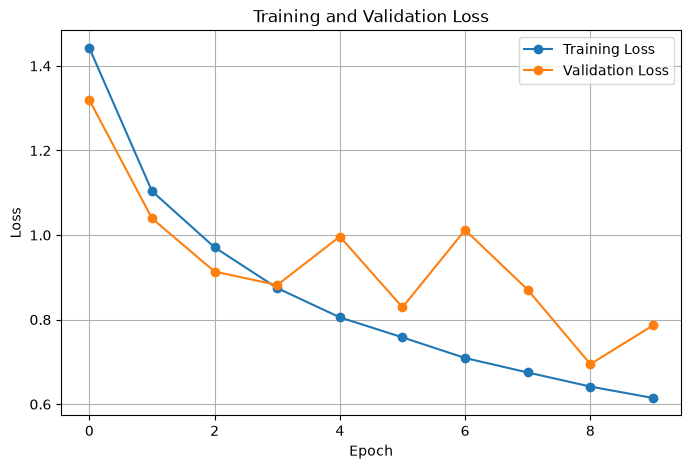

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_loss"], marker="o", label="Training Loss")
plt.plot(history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

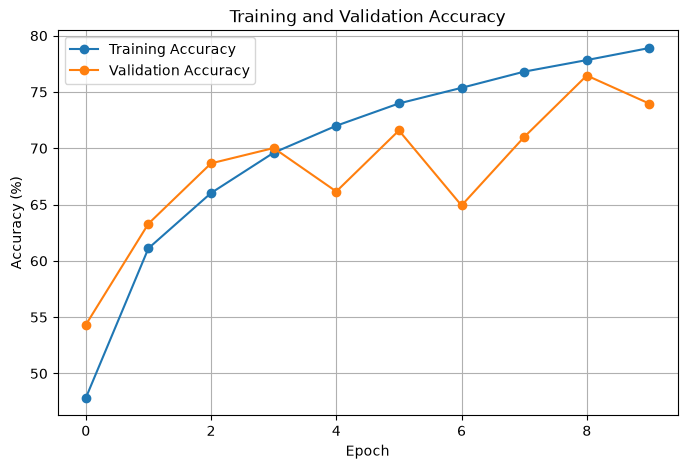

In [40]:
plt.figure(figsize=(8, 5))

plt.plot(history["train_acc"], marker="o", label="Training Accuracy")
plt.plot(history["val_acc"], marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()